# STM — data import and exploration
This notebook covers data import and exploration only, without a target or model. Detailed tables remain available as variables even when their display is limited.

## Import
The files have an `.xls` extension, but contain UTF-8 delimited text: use `read_csv`, not `read_excel`.

Install: `uv add pandas numpy matplotlib python-dotenv jupyterlab`. Place `.env` at the project root and the notebook in `notebooks/`, then launch Jupyter from the project.
```dotenv
INCIDENTS_PATH="data/Incidents métro_20260707.xls"
KM_PATH="data/Kilométrage métro planifé_20260707.xls"
```
Paths are relative to the `.env` directory. Use the exact filenames, including accents. Run the cells in order.


In [53]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import dotenv_values

try:
    from IPython.display import display
except ImportError:
    display = lambda value: print(value.to_string() if isinstance(value, (pd.DataFrame, pd.Series)) else value)

root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())
src_dir = root_dir / 'src'
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

from data_exploration_functions import (
    choose_day,
    day_incident,
    minutes,
    normalize_run,
    parse_lines,
    profile_table,
    resolve_data_path,
)

date_cols = {
    'Jour calendaire',
    'Année civile',
    'Année civile/mois',
    'Année civile/semaine',
}

binary_cols = {
    'CAT',
    'Porte',
    'Urgence métro',
    'Dommage matériel',
    'KFS',
}

line_map = {
    '1': 'Ligne verte',
    '2': 'Ligne orange',
    '4': 'Ligne jaune',
    '5': 'Ligne bleue',
}

weekday_map = {0: 'Monday', 1: 'Tuesday', 2: 'Wednesday', 3: 'Thursday', 4: 'Friday', 5: 'Saturday', 6: 'Sunday'}
duration_order = [
    '02 min et moins', '03 à 04 min', '05 à 09 min',
    '10 à 14 min', '15 à 19 min', '20 à 24 min',
    '25 à 29 min', '30 min et plus',
]
mid = dict(zip(duration_order, [1, 3.5, 7, 12, 17, 22, 27, np.nan]))

working_dir = Path.cwd().resolve()
env_path = next(
    (folder / '.env' for folder in [working_dir, *working_dir.parents] if (folder / '.env').is_file()),
    None,
)

if env_path is None:
    raise FileNotFoundError(
        'No .env file found. Place it at the project root and launch Jupyter from this project.'
    )

project_root = env_path.parent
config = dotenv_values(env_path)
print('Configuration file:', env_path)
print('Relative path base:', project_root)

Configuration file: C:\Users\antoi\Documents\TobboganLabs\Home Exercice\DS_challenge\.env
Relative path base: C:\Users\antoi\Documents\TobboganLabs\Home Exercice\DS_challenge


In [54]:
incidents_path = resolve_data_path(config, env_path, project_root, 'INCIDENTS_PATH')
mileage_path = resolve_data_path(config, env_path, project_root, 'KM_PATH')

print('Incidents:', incidents_path)
print('Mileage:', mileage_path)

Incidents: C:\Users\antoi\Documents\TobboganLabs\Home Exercice\DS_challenge\data\Incidents métro_20260707.xls
Mileage: C:\Users\antoi\Documents\TobboganLabs\Home Exercice\DS_challenge\data\Kilométrage métro planifé_20260707.xls


In [55]:
incidents_raw = pd.read_csv(
    incidents_path,
    sep=";",
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False,
)

mileage_raw = pd.read_csv(
    mileage_path,
    sep=",",
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False,
)

In [56]:
incidents = incidents_raw.copy()
mileage = mileage_raw.copy()

print('Import complete. Tables are ready for exploration.')

Import complete. Tables are ready for exploration.


## 1. Table profiling
Imported types, missing values and markers, number of categories, frequent and rare categories (≤5 occurrences). Rare does not mean invalid: business rules will be reviewed during cleaning. No business type is inferred automatically.


In [57]:
incident_profile = profile_table(incidents_raw, date_cols=date_cols, binary_cols=binary_cols)
mileage_profile = profile_table(mileage_raw, date_cols=date_cols, binary_cols=binary_cols)
display(incident_profile)
display(mileage_profile)


,field_kind,imported_type,pandas_missing,empty_or_whitespace,#,#N/A,Non affecté,category_count,rare_category_count_<=5,frequent_categories,rare_examples
column,,,,,,,,,,,
Numero d'incident,Code/category/text to review,str,0,0,0,0,0,45561,45561,"{'S01011901': 1, 'S01011902': 1, 'S01011903': ...","{'S01011901': 1, 'S01011902': 1, 'S01011903': ..."
Type d'incident,Code/category/text to review,str,0,0,0,0,0,2,0,"{'T': 29167, 'S': 16394}",{}
Cause primaire,Code/category/text to review,str,0,0,0,482,0,6,0,"{'Autres': 18082, 'Clientèle': 15693, 'Équipem...",{}
Cause secondaire,Code/category/text to review,str,0,0,0,482,0,21,1,"{'Autres': 16394, 'Méfait volontaire': 9200, '...",{'Matériel roulant': 5}
Symptome,Code/category/text to review,str,0,0,0,377,0,8,0,"{'Clientèle': 24397, 'Matériel roulant': 7750,...",{}
Ligne,Code/category/text to review,str,0,0,0,0,103,22,9,"{'Ligne verte': 20047, 'Ligne orange': 17994, ...","{'Ligne 2, 4': 5, 'Ligne 2, 1, 5': 4, 'Ligne 1..."
Numéro de tournée,Code/category/text to review,str,0,0,21846,0,0,168,78,"{'#': 21846, '1': 1074, '4': 969, '5': 954, '3...","{'59': 5, '97': 5, '328': 5, '89': 5, '94': 5,..."
Heure de l'incident,Code/category/text to review,str,0,0,0,0,0,1439,87,"{'05:30': 209, '05:00': 140, '05:05': 125, '05...","{'03:10': 5, '03:46': 5, '02:48': 5, '03:57': ..."
Heure de reprise,Code/category/text to review,str,0,0,0,0,0,1549,221,"{'05:35': 72, '16:26': 65, '15:20': 62, '18:15...","{'04:37': 5, '29:10:00': 5, '26:41:00': 5, '26..."


,field_kind,imported_type,pandas_missing,empty_or_whitespace,#,#N/A,Non affecté,category_count,rare_category_count_<=5,frequent_categories,rare_examples
column,,,,,,,,,,,
Ligne,Code/category/text to review,str,0,0,0,0,0,4,0,"{'Ligne bleue': 2118, 'Ligne jaune': 2118, 'Li...",{}
Période Exploitation,Code/category/text to review,str,0,0,1536,0,0,28,0,"{'#': 1536, '19M': 336, '22MB': 336, '23MB': 3...",{}
Type de Jour,Code/category/text to review,str,0,0,0,0,1536,8,0,"{'Semaine': 4788, 'Non affecté': 1536, 'Dimanc...",{}
Tournée,Code/category/text to review,str,0,0,0,0,0,1,0,{'001': 8472},{}
Année civile,Date/period,str,0,0,0,0,0,5,0,"{'2019': 2920, '2020': 1540, '2021': 1460, '20...",{}
Année civile/mois,Date/period,str,0,0,0,0,0,57,0,"{'2019-01': 248, '2019-03': 248, '2019-05': 24...",{}
Année civile/semaine,Date/period,str,0,0,0,0,0,248,0,"{'2019-01-07': 56, '2019-01-14': 56, '2019-01-...",{}
Jour calendaire,Date/period,str,0,0,0,0,0,1734,1350,"{'2019-01-06': 8, '2019-01-02': 8, '2019-01-05...","{'2020-01-12': 4, '2020-01-19': 4, '2020-01-26..."
Jour de la semaine,Code/category/text to review,str,0,0,0,0,0,7,0,"{'Mercredi': 1212, 'Samedi': 1212, 'Jeudi': 12...",{}


## 2. Timeline, shared coverage, train runs and potential keys
The shared window is the intersection of the date ranges. Actual coverage by line and day is checked separately. Shared columns are not automatically join keys: a month or year cannot uniquely identify a record.

Train run codes are normalized to compare `001` and `1`. The `#` marker remains an absence; a shared code does not guarantee the same meaning or aggregation level in both tables.


,table,start,end,distinct_days,invalid_dates
0,incidents,2019-01-01,2025-09-30,2465,0
1,km,2019-01-01,2023-09-30,1734,0


Shared window: 2019-01-01 00:00:00 → 2023-09-30 00:00:00
Incidents within this window: 30793


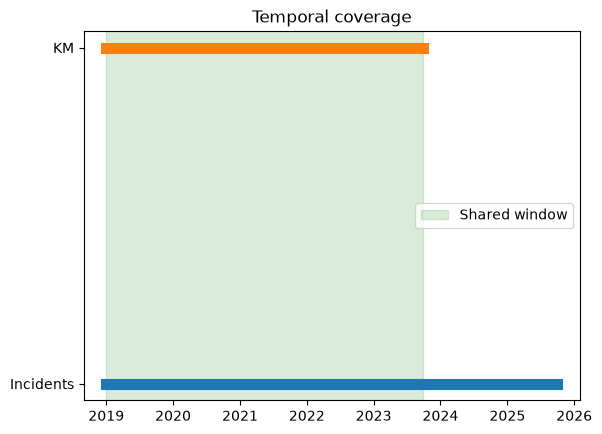

Exact shared columns: ['Année civile', 'Année civile/mois', 'Jour calendaire', 'Jour de la semaine', 'Ligne', 'Mois calendrier']


,incident_field,mileage_field,usage
0,Ligne,Ligne,Candidate after line normalization
1,Jour calendaire,Jour calendaire,Candidate exact date
2,Numéro de tournée,Tournée,Verify coding and granularity
3,Année civile/mois,Année civile/mois,Monthly aggregation only; different formats
4,Jour de la semaine,Jour de la semaine,Calendar check; different representations


Distinct incident/mileage runs: 167 1 intersection: ['1']
Incidents with a recorded run (%): 52.05109633238955
Incidents with a run code present in mileage, across all dates (%): 2.357279251991835
A shared code does not establish join validity.


,n,recorded,distinct
date,,,
2019,7944,4331,89
2020,5640,3028,87
2021,5476,2922,88
2022,6540,3409,88
2023,7200,3612,90
2024,7922,4066,101
2025,4839,2347,86


Tournée
001    8472
Name: count, dtype: int64

In [58]:
incidents['date'] = pd.to_datetime(incidents['Jour calendaire'], errors='coerce')
mileage['date'] = pd.to_datetime(mileage['Jour calendaire'], errors='coerce')
mileage['km'] = pd.to_numeric(mileage['KM planifié'].str.replace(',', '.', regex=False), errors='coerce')
coverage = pd.DataFrame([
    {
        'table': name,
        'start': table.date.min(),
        'end': table.date.max(),
        'distinct_days': table.date.nunique(),
        'invalid_dates': table.date.isna().sum(),
    }
    for name, table in [('incidents', incidents), ('km', mileage)]
])
display(coverage)
common_start = max(incidents.date.min(), mileage.date.min())
common_end = min(incidents.date.max(), mileage.date.max())
print('Shared window:', common_start, '→', common_end)
print('Incidents within this window:', incidents.date.between(common_start, common_end).sum())
fig, ax = plt.subplots()
for i, row in coverage.iterrows():
    ax.plot([row['start'], row['end']], [i, i], linewidth=8)
ax.axvspan(common_start, common_end, alpha=0.15, color='green', label='Shared window')
ax.set_yticks([0, 1], ['Incidents', 'KM'])
ax.legend()
ax.set_title('Temporal coverage')
plt.show()
common_columns = sorted(set(incidents_raw.columns) & set(mileage_raw.columns))
print('Exact shared columns:', common_columns)
join_candidates = pd.DataFrame({
    'incident_field': ['Ligne', 'Jour calendaire', 'Numéro de tournée', 'Année civile/mois', 'Jour de la semaine'],
    'mileage_field': ['Ligne', 'Jour calendaire', 'Tournée', 'Année civile/mois', 'Jour de la semaine'],
    'usage': [
        'Candidate after line normalization',
        'Candidate exact date',
        'Verify coding and granularity',
        'Monthly aggregation only; different formats',
        'Calendar check; different representations',
    ],
})
display(join_candidates)
incidents['normalized_run'] = normalize_run(incidents['Numéro de tournée'])
mileage['normalized_run'] = normalize_run(mileage['Tournée'])
a = set(incidents.normalized_run.dropna())
b = set(mileage.normalized_run.dropna())
print('Distinct incident/mileage runs:', len(a), len(b), 'intersection:', sorted(a & b))
print('Incidents with a recorded run (%):', 100 * incidents.normalized_run.notna().mean())
print('Incidents with a run code present in mileage, across all dates (%):', 100 * incidents.normalized_run.isin(b).mean())
print('A shared code does not establish join validity.')
display(incidents.groupby(incidents.date.dt.year).normalized_run.agg(n='size', recorded='count', distinct='nunique'))
display(mileage['Tournée'].value_counts())

## 3. Lines, locations and mileage
Line combinations are expanded only for analyses by line. A multi-line incident is counted once for each affected line, so totals by line may exceed the number of unique incidents.

The number of distinct `Code de lieu` values counts labels, not validated stations. Components separated by `/` are also counted for exploratory purposes.

Mileage is summed by line and date after auditing. The code stops if a key has multiple positive values, since their additivity would require confirmation. Missing days remain missing, never zero. The chart shows the mean daily mileage for each Monday–Sunday week, by line and overall; partial weeks use the available days.


Recognized lines: 4
Raw line categories: 22 multi-line incidents: 378


,incidents,location_code_count
analysis_line,,
Ligne verte,20357,95
Ligne orange,18365,110
Ligne bleue,4743,39
Ligne jaune,2537,23
Inconnue,104,5


analysis_line
Inconnue         5
Ligne bleue     29
Ligne jaune     21
Ligne orange    87
Ligne verte     70
Name: distinct_location_components, dtype: int64

n
1    5400
2    1536
Name: count, dtype: int64

km_total  mean_daily_mileage  observed_days  \
Ligne        Year                                                    
Ligne bleue  2019  8.443931e+06        23134.058301            365   
             2020  8.308218e+06        22700.049836            366   
             2021  7.865159e+06        21548.380274            365   
             2022  7.868827e+06        21558.429370            365   
             2023  5.746745e+06        21050.349011            273   
Ligne jaune  2019  4.895769e+06        13413.065918            365   
             2020  4.753353e+06        12987.301967            366   
             2021  4.552771e+06        12473.344110            365   
             2022  4.559018e+06        12490.459397            365   
             2023  4.552095e+06        16674.341538            273   
Ligne orange 2019  4.400413e+07       120559.247063            365   
             2020  4.275955e+07       116829.369492            366   
             2021  4.108229e+07       112554.221770            365   
             2022  4.112371e+07       112667.711129            365   
             2023  2.983575e+07       109288.465121            273   
Ligne verte  2019  3.255122e+07        89181.426082            365   
             2020  3.217867e+07        87919.860984            366   
             2021  3.080206e+07        84389.208658            365   
             2022  3.080165e+07        84388.093151            365   
             2023  2.142435e+07        78477.480000            273   

                   expected_days  complete_year  
Ligne        Year                                
Ligne bleue  2019            365           True  
             2020            366           True  
             2021            365           True  
             2022            365           True  
             2023            365          False  
Ligne jaune  2019            365           True  
             2020            366           True  
             2021            365           True  
             2022            365           True  
             2023            365          False  
Ligne orange 2019            365           True  
             2020            366           True  
             2021            365           True  
             2022            365           True  
             2023            365          False  
Ligne verte  2019            365           True  
             2020            366           True  
             2021            365           True  
             2022            365           True  
             2023            365          False

Mean annual mileage: complete years only, without extrapolating 2023.


,annual_mean,year_count
Ligne,,
Ligne bleue,8.121534e+06,4
Ligne jaune,4.690227e+06,4
Ligne orange,4.224242e+07,4
Ligne verte,3.158340e+07,4


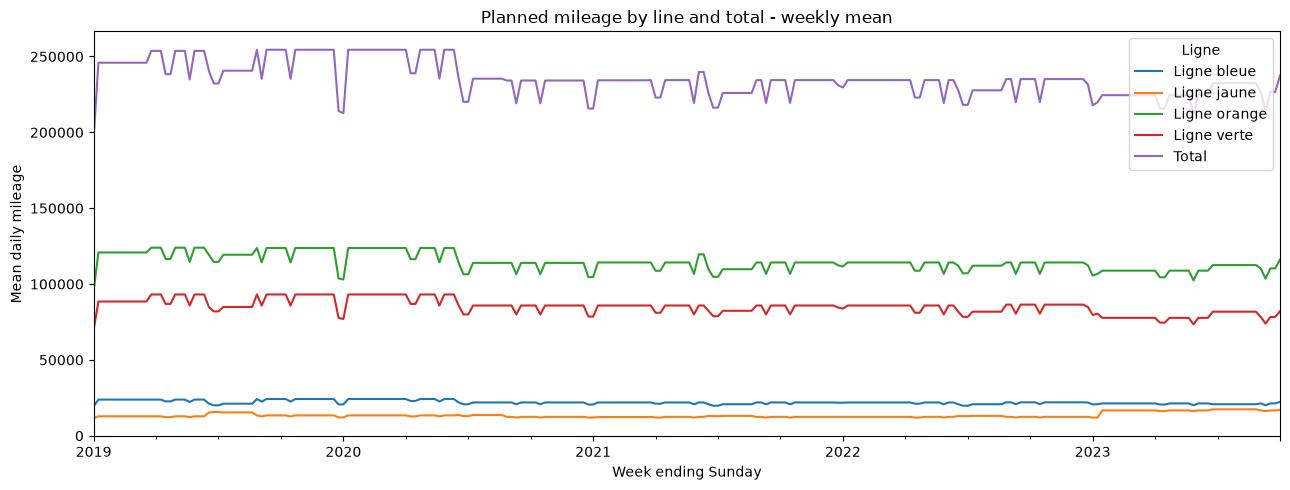

_merge,left_only,both
date,,
2019,0.06,99.94
2020,0.09,99.91
2021,0.29,99.71
2022,0.27,99.73
2023,28.04,71.96
2024,100.00,0.00
2025,100.00,0.00


In [59]:
incidents['lines'] = incidents.Ligne.map(lambda value: parse_lines(value, line_map=line_map))
incidents['line_count'] = incidents.lines.map(len)
incidents_by_line = incidents.explode('lines', ignore_index=True).rename(columns={'lines': 'analysis_line'})
incidents_by_line['analysis_line'] = incidents_by_line.analysis_line.fillna('Inconnue')
print('Recognized lines:', incidents_by_line.loc[incidents_by_line.analysis_line.ne('Inconnue'), 'analysis_line'].nunique())
print('Raw line categories:', incidents.Ligne.nunique(), 'multi-line incidents:', incidents.line_count.gt(1).sum())
line_summary = incidents_by_line.groupby('analysis_line').agg(incidents=("Numero d'incident", 'nunique'), location_code_count=('Code de lieu', 'nunique')).sort_values('incidents', ascending=False)
display(line_summary)
location_components = incidents_by_line.assign(location_component=incidents_by_line['Code de lieu'].str.split('/')).explode('location_component')
location_components['location_component'] = location_components.location_component.str.strip()
display(location_components.groupby('analysis_line').location_component.nunique().rename('distinct_location_components'))
mileage_audit = mileage.groupby(['Ligne', 'date']).agg(n=('km', 'size'), positive_values=('km', lambda s: s.gt(0).sum()))
display(mileage_audit.n.value_counts())
if mileage.km.isna().any() or mileage.km.lt(0).any():
    raise ValueError('Invalid mileage to investigate')
if mileage_audit.positive_values.gt(1).any():
    raise ValueError('Multiple positive mileage values per key: confirm before aggregation')
daily_mileage = mileage.groupby(['Ligne', 'date'], as_index=False).km.sum()
annual_mileage = daily_mileage.groupby(['Ligne', daily_mileage.date.dt.year]).agg(km_total=('km', 'sum'), mean_daily_mileage=('km', 'mean'), observed_days=('date', 'nunique'))
annual_mileage.index.names = ['Ligne', 'Year']
annual_mileage['expected_days'] = annual_mileage.index.get_level_values('Year').map(lambda y: 366 if pd.Timestamp(y, 12, 31).is_leap_year else 365)
annual_mileage['complete_year'] = annual_mileage.observed_days.eq(annual_mileage.expected_days)
display(annual_mileage)
mean_annual_mileage = annual_mileage.loc[annual_mileage['complete_year']].groupby('Ligne').km_total.agg(annual_mean='mean', year_count='size')
print('Mean annual mileage: complete years only, without extrapolating 2023.')
display(mean_annual_mileage)
calendar = pd.date_range(daily_mileage.date.min(), daily_mileage.date.max(), freq='D')
km_daily = daily_mileage.pivot(index='date', columns='Ligne', values='km').reindex(calendar)
km_daily['Total'] = km_daily.sum(axis=1, min_count=len(line_map))
# Mean daily mileage within each distinct Monday-Sunday week.
weekly_mileage = km_daily.resample('W-SUN', closed='right', label='right').mean()
weekly_mileage.plot(figsize=(13, 5), title='Planned mileage by line and total - weekly mean')
plt.xlabel('Week ending Sunday')
plt.ylabel('Mean daily mileage')
plt.tight_layout()
plt.show()
# Partial weeks: average the available days, without imputation.
joined_incidents = incidents_by_line.merge(daily_mileage, left_on=['analysis_line', 'date'], right_on=['Ligne', 'date'], how='left', validate='many_to_one', indicator=True)
assert len(joined_incidents) == len(incidents_by_line)
display(pd.crosstab(joined_incidents.date.dt.year, joined_incidents['_merge'], normalize='index').mul(100).round(2))

## 4. Monthly incident counts
Monthly counts of unique recorded identifiers. These volumes are not adjusted for service supply or ridership. A decrease may also reflect coverage or reporting.


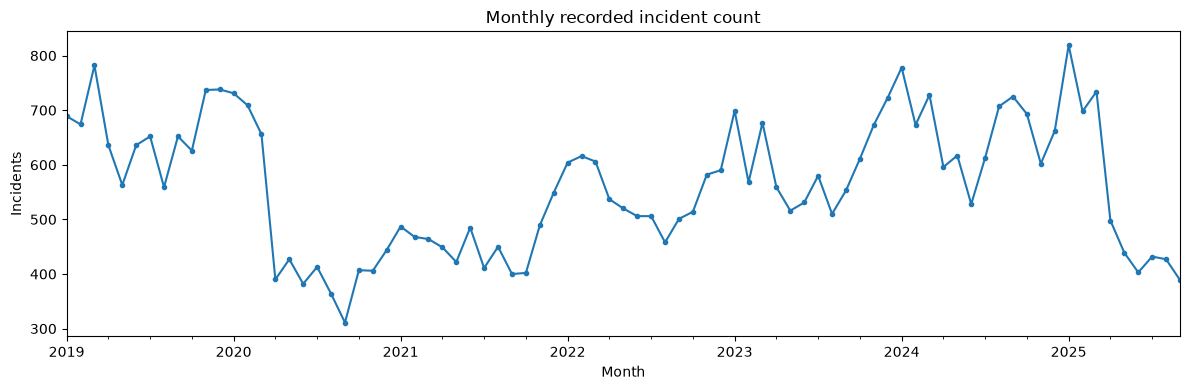

In [60]:
monthly_incidents=incidents.groupby(incidents.date.dt.to_period('M'))["Numero d'incident"].nunique()
monthly_incidents.index=monthly_incidents.index.to_timestamp()
monthly_incidents.plot(figsize=(12,4),title='Monthly recorded incident count',marker='.')
plt.xlabel('Month');plt.ylabel('Incidents');plt.tight_layout();plt.show()

## 5. Calculated duration and text-based classes
Calculated duration is **service resumption − start**, with midnight crossings handled using modulo 24 hours. Without a resumption date, durations ≥24 hours cannot be detected. For `S`, the times describe a station incident; for `T`, they describe a service delay, so discrepancies have different meanings.

Text-based duration classes are converted to numeric bounds. A **conventional class midpoint** is also used: 1, 3.5, 7, 12, 17, 22 and 27 minutes. This is not an exact duration. The “30 min et plus” class has no known midpoint: its estimate remains missing, and its lower bound is 30.

Mean signed and absolute discrepancies are therefore calculated for closed classes only. For all classes, distance from the interval measures disagreement with the bounds without inventing a duration. Integer bounds are used as displayed; the source's rounding rule is unknown.
This section displays charts only; intermediate statistics remain available as Python variables.


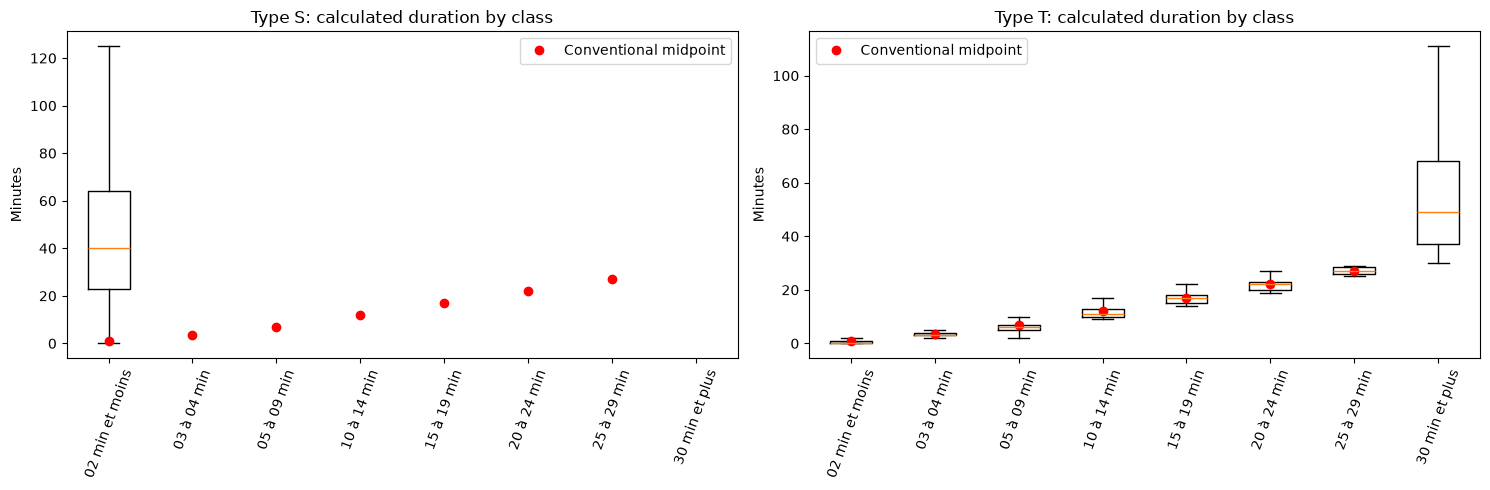

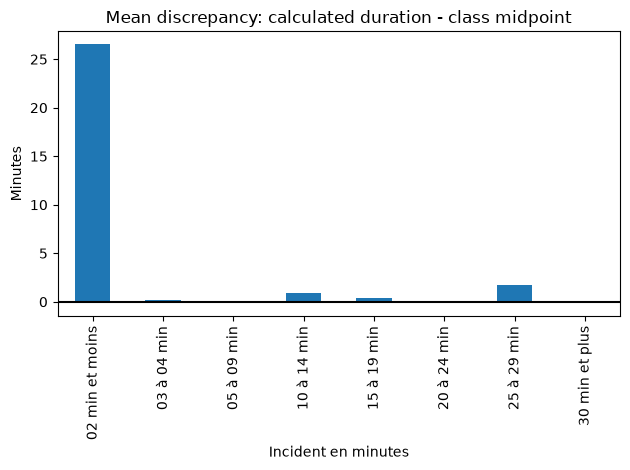

In [61]:
start = minutes(incidents["Heure de l'incident"])
end = minutes(incidents["Heure de reprise"])

incidents['calculated_duration'] = (end - start) % 1440
incidents['estimated_class_duration'] = incidents["Incident en minutes"].map(mid)
incidents['signed_discrepancy'] = (
    incidents['calculated_duration'] - incidents['estimated_class_duration']
)

# Chart 1: calculated duration by class, separately for S and T.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, incident_type in zip(axes, ["S", "T"]):
    group = incidents.loc[
        incidents["Type d'incident"].eq(incident_type)
    ]

    values = [
        group.loc[
            group["Incident en minutes"].eq(duration_class),
            'calculated_duration',
        ].dropna().to_numpy()
        for duration_class in duration_order
    ]

    ax.boxplot(
        [v if len(v) else [np.nan] for v in values],
        tick_labels=duration_order,
        showfliers=False,
    )
    ax.plot(
        np.arange(1, len(duration_order) + 1),
        [mid[duration_class] for duration_class in duration_order],
        "ro",
        label='Conventional midpoint',
    )
    ax.tick_params(axis="x", rotation=70)
    ax.set_title(f"Type {incident_type}: calculated duration by class")
    ax.set_ylabel("Minutes")
    ax.legend()

plt.tight_layout()
plt.show()

# Chart 2: mean signed discrepancy by class.
mean_discrepancy = (
    incidents.groupby("Incident en minutes")['signed_discrepancy']
    .mean()
    .reindex(duration_order)
)

mean_discrepancy.plot.bar(
    title='Mean discrepancy: calculated duration - class midpoint'
)
plt.axhline(0, color="black")
plt.ylabel("Minutes")
plt.tight_layout()
plt.show()

## 6. Symptoms and causes
Secondary causes are detailed within each symptom–primary cause pair; percentages sum to 100% within each pair. A second percentage expresses each branch as a share of its symptom.

Train incident causes are determined after analysis. This section is retrospective and does not establish their availability at incident onset. The pie chart shows the symptom distribution; the stacked bar chart shows primary causes **within each symptom**.
The harmonized palette assigns a fixed colour to each symptom. Stacked segments represent primary causes; labels and markers retain the symptom's colour.


,Symptome,Cause primaire,Cause secondaire,Count,Secondary_pct_within_parent,Branch_pct_within_symptom
0,#N/A,Autres,Autres,294,97.67,77.98
1,#N/A,Autres,Causes externes,4,1.33,1.06
2,#N/A,Autres,Contrats Réno-Système,2,0.66,0.53
3,#N/A,Autres,Pers. / Équipement Externe,1,0.33,0.27
4,#N/A,Clientèle,Méfait volontaire,54,100.00,14.32
5,#N/A,Exploitation trains,"Ligne 1, 2, 4, 5",4,100.00,1.06
6,#N/A,Matériel roulant,MPM-10,4,57.14,1.06
7,#N/A,Matériel roulant,MR-73,3,42.86,0.80
8,#N/A,Équipements fixes,Service TCPE,8,72.73,2.12
9,#N/A,Équipements fixes,Service aux trains,3,27.27,0.80


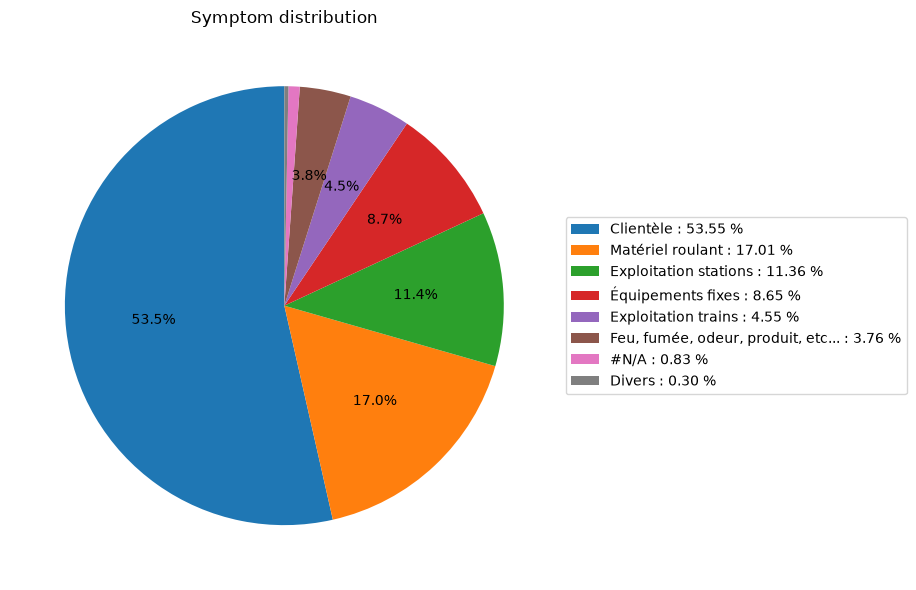

Cause primaire,#N/A,Autres,Clientèle,Exploitation trains,Matériel roulant,Équipements fixes
Symptome,,,,,,
#N/A,0.00,79.84,14.32,1.06,1.86,2.92
Clientèle,1.00,46.66,51.37,0.55,0.10,0.33
Divers,0.00,67.65,19.12,2.21,2.94,8.09
Exploitation stations,1.02,91.04,1.28,0.12,0.08,6.47
Exploitation trains,0.63,3.38,3.72,74.31,15.93,2.03
"Feu, fumée, odeur, produit, etc...",4.15,63.67,19.51,0.88,3.56,8.24
Matériel roulant,0.90,0.94,25.06,5.96,45.83,21.30
Équipements fixes,0.81,9.13,16.79,2.41,4.67,66.18


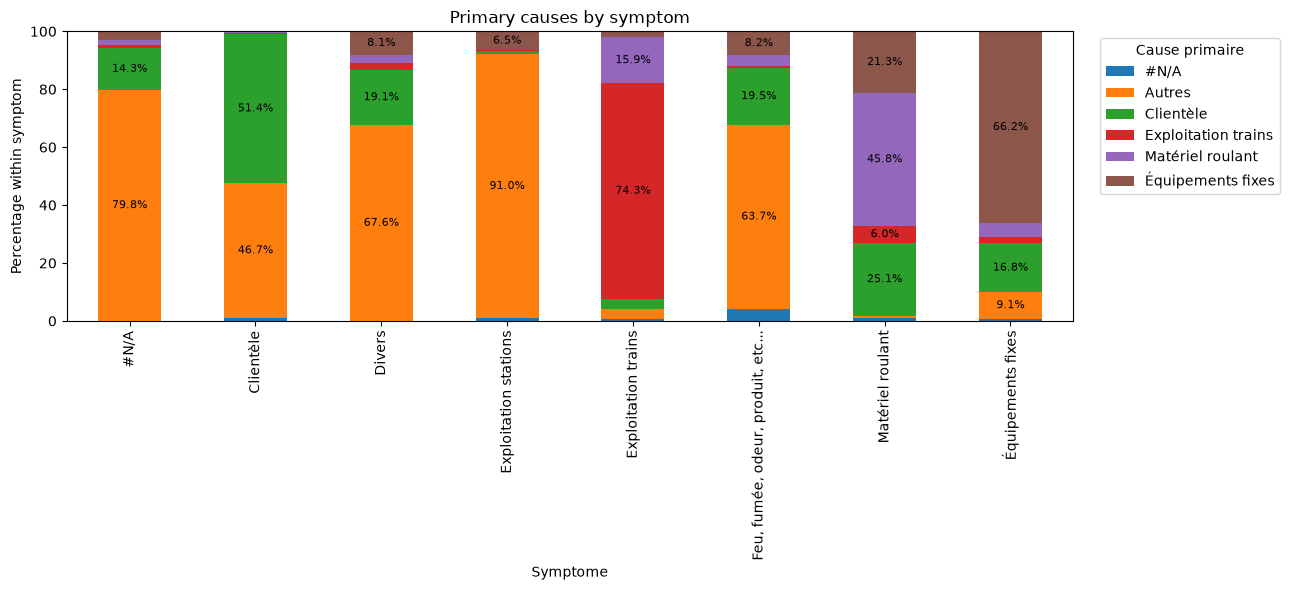

In [62]:
parents = ["Symptome", "Cause primaire"]

counts = (
    incidents.groupby(parents, dropna=False)["Cause secondaire"]
    .value_counts(dropna=False)
    .rename('Count')
)

pct = (
    incidents.groupby(parents, dropna=False)["Cause secondaire"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .rename('Secondary_pct_within_parent')
)

cause_hierarchy = pd.concat([counts, pct], axis=1).reset_index()

cause_hierarchy['Branch_pct_within_symptom'] = (
    100 * cause_hierarchy['Count']
    / cause_hierarchy.groupby("Symptome")['Count'].transform("sum")
)

cause_hierarchy = cause_hierarchy.sort_values(
    parents + ['Count'],
    ascending=[True, True, False],
)

with pd.option_context("display.max_rows", None):
    display(cause_hierarchy.round(2))

# Symptom pie chart.
symptom_distribution = incidents["Symptome"].value_counts(dropna=False)

fig, ax = plt.subplots(figsize=(10, 6))

wedges, _, _ = ax.pie(
    symptom_distribution.values,
    autopct=lambda p: f"{p:.1f}%" if p >= 2 else "",
    startangle=90,
)

ax.legend(
    wedges,
    [
        f"{k} : {100 * v / len(incidents):.2f} %"
        for k, v in symptom_distribution.items()
    ],
    loc="center left",
    bbox_to_anchor=(1, 0.5),
)
ax.set_title('Symptom distribution')
plt.tight_layout()
plt.show()

# Primary cause distribution within each symptom.
symptom_cause_counts = pd.crosstab(
    incidents["Symptome"],
    incidents["Cause primaire"],
)

symptom_cause_percentages = (
    symptom_cause_counts
    .div(symptom_cause_counts.sum(axis=1), axis=0)
    .mul(100)
)

display(symptom_cause_percentages.round(2))

ax = symptom_cause_percentages.plot.bar(
    stacked=True,
    figsize=(13, 6),
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[
            f"{v:.1f}%" if v >= 5 else ""
            for v in container.datavalues
        ],
        label_type="center",
        fontsize=8,
    )

ax.set_ylim(0, 100)
ax.set_ylabel('Percentage within symptom')
ax.set_title('Primary causes by symptom')
ax.legend(title="Cause primaire", bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()

## 8. Day type
Two concepts are distinguished: **day of the week**, calculated from the date and available for all incidents, and the **operating day type**, supplied by the mileage file.

For the latter, joining is limited to mileage coverage. Technical “Non affecté” labels are ignored only when an informed type exists for the same line and date. Conflicting informed types are labelled “Ambigu”, rather than resolved arbitrarily. A multi-line incident may match several types and then receives “Plusieurs types”. Dates outside coverage remain a separate category; their operating type is never imputed from the weekday.
All tables show percentages: overall across incidents, then within each line or symptom. Unmatched cases remain in the denominator.


In [63]:
incidents['weekday'] = incidents.date.dt.dayofweek.map(weekday_map)
# incidents_by_line was created before this column: calculate it separately.
incidents_by_line['weekday'] = incidents_by_line.date.dt.dayofweek.map(weekday_map)
weekday_distribution = incidents.weekday.value_counts(normalize=True).mul(100).rename('Percentage (%)').to_frame()
display(weekday_distribution.round(2))
display(pd.crosstab(incidents_by_line.analysis_line, incidents_by_line.weekday, normalize='index').mul(100).round(2).reindex(columns=weekday_distribution.index))
display(pd.crosstab(incidents.Symptome, incidents.weekday, normalize='index').mul(100).round(2).reindex(columns=weekday_distribution.index))
day_types = mileage.groupby(['Ligne', 'date'])['Type de Jour'].agg(choose_day).reset_index()
line_days = incidents_by_line.merge(day_types, left_on=['analysis_line', 'date'], right_on=['Ligne', 'date'], how='left', validate='many_to_one')
line_days['Type de Jour'] = line_days['Type de Jour'].fillna('Unmatched / outside coverage')
incident_day_type = line_days.groupby("Numero d'incident")['Type de Jour'].agg(day_incident)
incidents['operating_day_type'] = incidents["Numero d'incident"].map(incident_day_type)
day_type_counts = incidents.operating_day_type.value_counts(normalize=True).mul(100).rename('Percentage (%)').to_frame()
display(day_type_counts.round(2))
display(pd.crosstab(line_days.analysis_line, line_days['Type de Jour'], normalize='index').mul(100).round(2).reindex(columns=day_type_counts.index, fill_value=0))
display(pd.crosstab(incidents.Symptome, incidents.operating_day_type, normalize='index').mul(100).round(2).reindex(columns=day_type_counts.index, fill_value=0))
print('Counts are not daily risk rates: the weekday category covers more days than Saturday/Sunday.')

,Percentage (%)
weekday,
Friday,16.06
Tuesday,15.05
Thursday,14.92
Wednesday,14.75
Monday,14.48
Saturday,12.94
Sunday,11.81


weekday,Friday,Tuesday,Thursday,Wednesday,Monday,Saturday,Sunday
analysis_line,,,,,,,
Inconnue,10.58,21.15,12.50,23.08,18.27,5.77,8.65
Ligne bleue,16.47,15.79,14.74,15.41,13.87,11.43,12.29
Ligne jaune,16.36,16.00,15.49,14.35,14.11,12.77,10.92
Ligne orange,16.16,15.09,14.94,14.64,14.56,13.12,11.49
Ligne verte,15.85,14.69,14.91,14.62,14.56,13.19,12.17


weekday,Friday,Tuesday,Thursday,Wednesday,Monday,Saturday,Sunday
Symptome,,,,,,,
#N/A,15.38,16.71,11.14,15.12,14.85,14.85,11.94
Clientèle,15.62,14.57,14.33,14.10,13.95,14.10,13.33
Divers,7.35,27.94,22.06,13.24,15.44,11.03,2.94
Exploitation stations,15.51,13.20,14.05,13.68,14.35,16.67,12.54
Exploitation trains,19.56,15.07,14.10,14.58,18.88,10.09,7.73
"Feu, fumée, odeur, produit, etc...",17.17,15.89,14.78,17.87,13.96,10.34,9.99
Matériel roulant,16.44,16.57,16.86,16.26,15.23,9.48,9.16
Équipements fixes,16.74,16.54,16.49,15.96,14.28,10.17,9.82


,Percentage (%)
operating_day_type,
Semaine,49.79
Unmatched / outside coverage,32.54
Samedi,8.44
Dimanche,7.74
Premième pér. fête,0.51
Deuxième pér. fête,0.51
Troisième pér. fête,0.31
Quatrième pér. fête,0.16


operating_day_type,Semaine,Unmatched / outside coverage,Samedi,Dimanche,Premième pér. fête,Deuxième pér. fête,Troisième pér. fête,Quatrième pér. fête
analysis_line,,,,,,,,
Inconnue,0.00,100.00,0.00,0.00,0.00,0.00,0.00,0.00
Ligne bleue,50.39,31.98,7.72,8.41,0.46,0.48,0.32,0.23
Ligne jaune,46.24,38.43,7.29,6.86,0.39,0.35,0.35,0.08
Ligne orange,50.04,32.30,8.66,7.53,0.52,0.55,0.29,0.13
Ligne verte,49.88,32.05,8.59,7.96,0.52,0.50,0.32,0.18


operating_day_type,Semaine,Unmatched / outside coverage,Samedi,Dimanche,Premième pér. fête,Deuxième pér. fête,Troisième pér. fête,Quatrième pér. fête
Symptome,,,,,,,,
#N/A,29.18,57.29,7.69,5.04,0.27,0.53,0.00,0.00
Clientèle,47.24,33.41,9.20,8.47,0.58,0.56,0.35,0.18
Divers,68.38,23.53,6.62,1.47,0.00,0.00,0.00,0.00
Exploitation stations,43.04,36.71,10.82,8.10,0.35,0.41,0.27,0.31
Exploitation trains,65.96,20.23,7.05,6.04,0.29,0.29,0.14,0.00
"Feu, fumée, odeur, produit, etc...",59.35,24.36,7.30,7.71,0.41,0.47,0.41,0.00
Matériel roulant,54.44,31.55,6.25,6.40,0.48,0.49,0.28,0.12
Équipements fixes,53.96,31.58,6.32,6.75,0.53,0.53,0.28,0.05


Counts are not daily risk rates: the weekday category covers more days than Saturday/Sunday.


## 9. Incident type — charts only
Volumes by type, symptom and line distributions, monthly trends and mean durations. The breakdown by line counts incident–line assignments and may count a multi-line incident several times. The text-based mean uses conventional class midpoints and excludes durations ≥30 minutes; the calculated mean has no such exclusion.


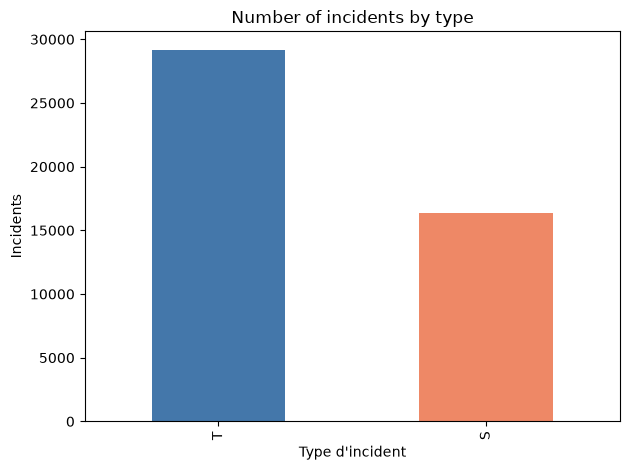

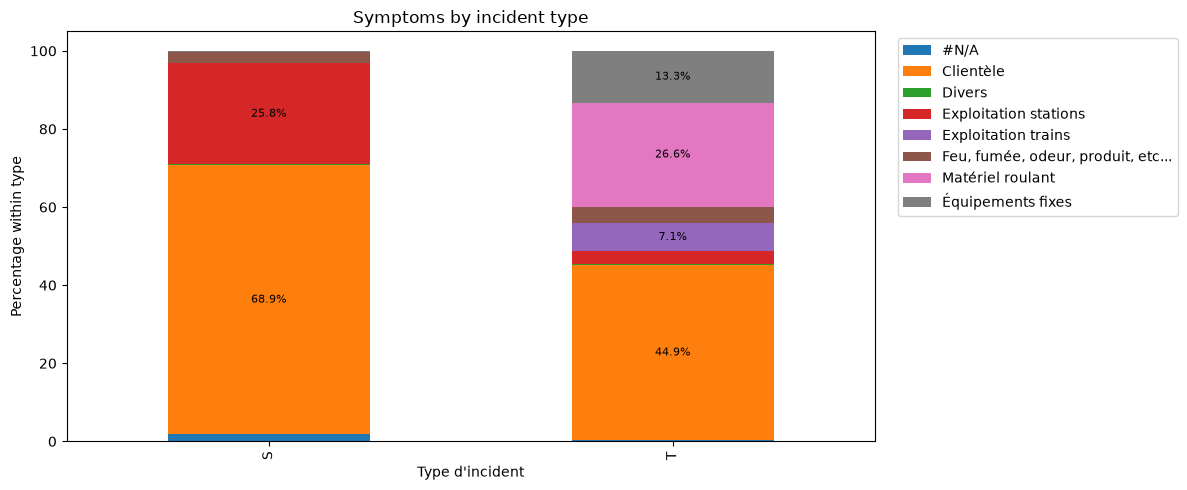

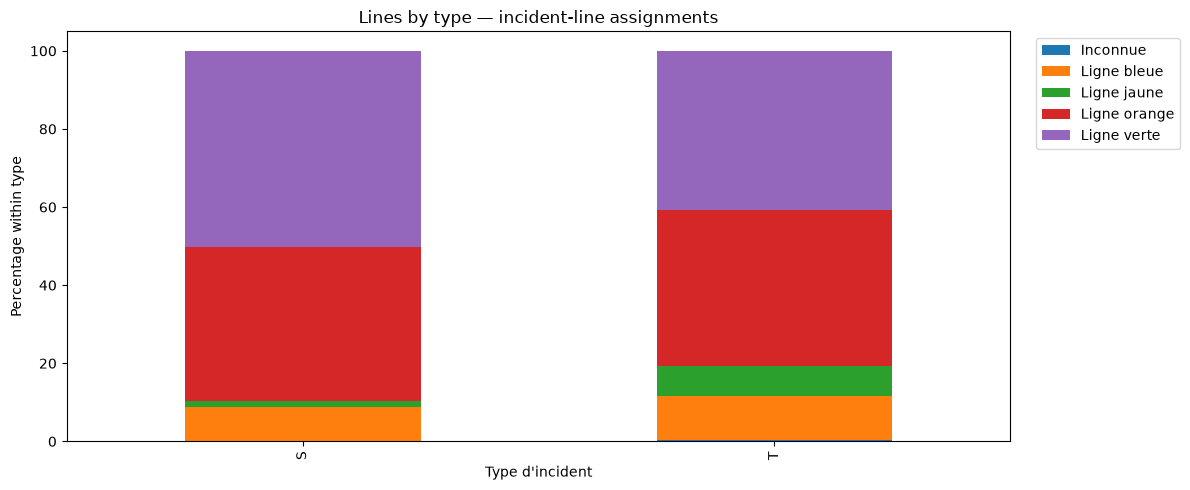

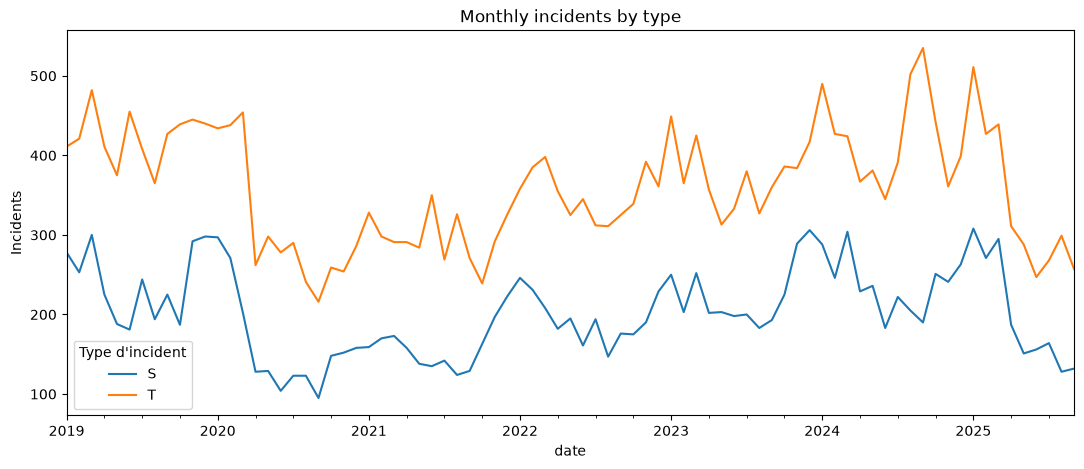

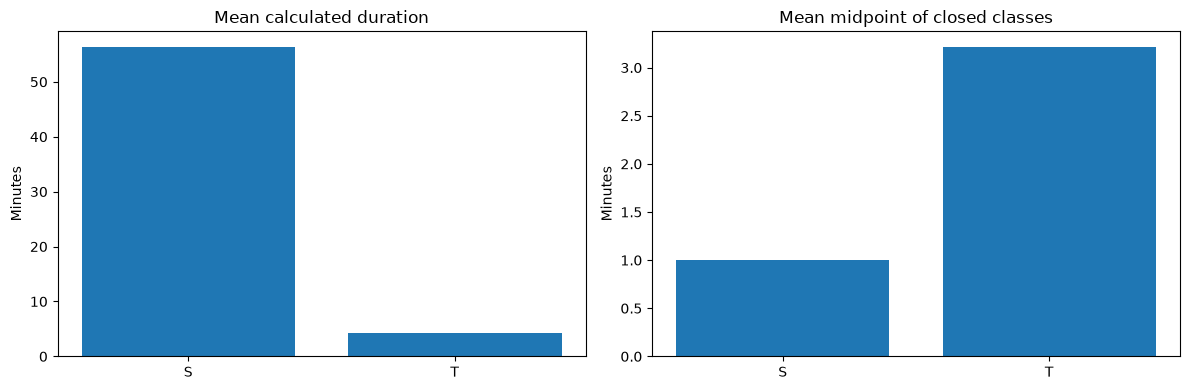

In [64]:
# Define the chart inputs used in this section.
if 'symptom_colors' not in globals():
    symptom_names = sorted(incidents['Symptome'].unique())
    symptom_colors = dict(zip(symptom_names, plt.get_cmap('tab10').colors * (1 + len(symptom_names) // 10)))
duration_by_type = incidents.groupby("Type d'incident").agg(
    mean_calculated_duration=('calculated_duration', 'mean'),
    mean_closed_class_midpoint=('estimated_class_duration', 'mean'),
)
type_counts=incidents["Type d'incident"].value_counts()
type_counts.plot.bar(title='Number of incidents by type',color=['#4477AA','#EE8866'])
plt.ylabel('Incidents');plt.tight_layout();plt.show()
# Each symptom retains its colour in the type × symptom breakdown.
type_symptom=pd.crosstab(incidents["Type d'incident"],incidents.Symptome,normalize='index').mul(100)
ax=type_symptom.plot.bar(stacked=True,color=[symptom_colors[c] for c in type_symptom.columns],figsize=(12,5))
for container in ax.containers:
    ax.bar_label(container,labels=[f'{v:.1f}%' if v>=5 else '' for v in container.datavalues],label_type='center',fontsize=8)
ax.set_title('Symptoms by incident type');ax.set_ylabel('Percentage within type');ax.legend(bbox_to_anchor=(1.02,1));plt.tight_layout();plt.show()
type_line=pd.crosstab(incidents_by_line["Type d'incident"],incidents_by_line.analysis_line,normalize='index').mul(100)
type_line.plot.bar(stacked=True,figsize=(12,5),title='Lines by type — incident-line assignments')
plt.ylabel('Percentage within type');plt.legend(bbox_to_anchor=(1.02,1));plt.tight_layout();plt.show()
type_time=pd.crosstab(incidents.date.dt.to_period('M'),incidents["Type d'incident"])
type_time.index=type_time.index.to_timestamp();type_time.plot(figsize=(13,5),title='Monthly incidents by type');plt.ylabel('Incidents');plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].bar(duration_by_type.index,duration_by_type['mean_calculated_duration']);axes[0].set_title('Mean calculated duration');axes[0].set_ylabel('Minutes')
axes[1].bar(duration_by_type.index,duration_by_type['mean_closed_class_midpoint']);axes[1].set_title('Mean midpoint of closed classes');axes[1].set_ylabel('Minutes')
plt.tight_layout();plt.show()